In [27]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, roc_auc_score
from pytorch_tabnet.tab_model import TabNetClassifier
import matplotlib.pyplot as plt


In [28]:

NPFC = pd.read_csv('NPFC-Test_Database_V2.csv')
# 1. Crear variable objetivo binaria (0: No concentrado, 1: Concentrado)
NPFC["Category"] = (NPFC["Selfreport_focus"] >= 3).astype(int)

bands = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']
for band in bands:
    NPFC[band] = NPFC[[f'{band}_TP9', f'{band}_AF7', f'{band}_AF8', f'{band}_TP10']].mean(axis=1)

eeg_features = bands 
# 2. Definir columnas de entrada (Emociones ResMaskNet + Ritmo Cardíaco + Sudoración)
"""
eeg_features = [
    'Delta_TP9', 'Delta_AF7', 'Delta_AF8', 'Delta_TP10',
    'Theta_TP9', 'Theta_AF7', 'Theta_AF8', 'Theta_TP10',
    'Alpha_TP9', 'Alpha_AF7', 'Alpha_AF8', 'Alpha_TP10',
    'Beta_TP9', 'Beta_AF7', 'Beta_AF8', 'Beta_TP10',
    'Gamma_TP9', 'Gamma_AF7', 'Gamma_AF8', 'Gamma_TP10'
]"""
emotion_cols = [
    'resmasknet_anger',
    'resmasknet_disgust',
    'resmasknet_fear',
    'resmasknet_happiness',
    'resmasknet_sadness',
    'resmasknet_surprise',
    'resmasknet_neutral'
]
physio_cols = [
    'EDA',
    'BVP',
    'Temperature'
]

feature_cols = emotion_cols + physio_cols + eeg_features

# Eliminar nulos si los hubiera en las columnas seleccionadas
df_clean = NPFC.dropna(subset=feature_cols + ['Category', 'Subject_ID']).copy()

X = df_clean[feature_cols].values
y = df_clean['Category'].values
groups = df_clean['Subject_ID'].values


In [29]:

# 3. División Train / Valid / Test agrupada por SubjectID (evita fuga de datos)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_val_idx, test_idx = next(gss_test.split(X, y, groups))

X_train_val, y_train_val, groups_train_val = X[train_val_idx], y[train_val_idx], groups[train_val_idx]
X_test, y_test = X[test_idx], y[test_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups_train_val))

X_train, y_train = X_train_val[train_idx], y_train_val[train_idx]
X_valid, y_valid = X_train_val[val_idx], y_train_val[val_idx]


In [30]:

# 4. Configurar el modelo TabNet
# Como todas las variables (probabilidades de emoción, HR, EDA) son numéricas continuas,
# no necesitamos cat_idxs ni cat_dims.
clf = TabNetClassifier(
    n_d=16,                          # Capacidad de la capa de decisión
    n_a=16,                          # Capacidad de atención (igual a n_d)
    n_steps=4,                       # Pasos secuenciales de atención
    gamma=1.5,                       # Reutilización de características
    lambda_sparse=1e-4,              # Regularización de dispersión en las máscaras
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    scheduler_params={"step_size": 10, "gamma": 0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type='entmax',              # 'entmax' suele dar mejores máscaras que 'sparsemax' en datos continuos
    seed=42,
    verbose=1
)

# 5. Entrenar el modelo
# Nota: Si las clases (0 y 1) están desbalanceadas, agrega weights=1 en clf.fit()
clf.fit(
    X_train=X_train, y_train=y_train,
    eval_set=[(X_train, y_train), (X_valid, y_valid)],
    eval_name=['train', 'valid'],
    eval_metric=['auc', 'accuracy'],
    max_epochs=100,
    patience=15,
    batch_size=512,                  # Batch grande dado que los datos están muestreados por segundo
    virtual_batch_size=128,
    weights=1                        # Balancea automáticamente el peso de las clases si hay desbalance
)


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.66365 | train_auc: 0.45424 | train_accuracy: 0.31617 | valid_auc: 0.52128 | valid_accuracy: 0.26722 |  0:00:06s
epoch 1  | loss: 0.59195 | train_auc: 0.43381 | train_accuracy: 0.31613 | valid_auc: 0.52581 | valid_accuracy: 0.26722 |  0:00:11s
epoch 2  | loss: 0.57051 | train_auc: 0.42386 | train_accuracy: 0.31713 | valid_auc: 0.461   | valid_accuracy: 0.26722 |  0:00:17s
epoch 3  | loss: 0.55601 | train_auc: 0.44085 | train_accuracy: 0.32988 | valid_auc: 0.47355 | valid_accuracy: 0.34962 |  0:00:22s
epoch 4  | loss: 0.5335  | train_auc: 0.4649  | train_accuracy: 0.4602  | valid_auc: 0.5898  | valid_accuracy: 0.57628 |  0:00:28s
epoch 5  | loss: 0.51568 | train_auc: 0.4768  | train_accuracy: 0.48464 | valid_auc: 0.52834 | valid_accuracy: 0.55536 |  0:00:33s
epoch 6  | loss: 0.49938 | train_auc: 0.5759  | train_accuracy: 0.59364 | valid_auc: 0.43526 | valid_accuracy: 0.53508 |  0:00:39s
epoch 7  | loss: 0.49682 | train_auc: 0.74207 | train_accuracy: 0.70985 | valid_auc

/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [31]:

# 6. Evaluar en participantes nunca antes vistos (Test)
preds = clf.predict(X_test)
probs = clf.predict_proba(X_test)[:, 1]

print(f"ROC-AUC en Test: {roc_auc_score(y_test, probs):.4f}")
print(classification_report(y_test, preds))

ROC-AUC en Test: 0.4039
              precision    recall  f1-score   support

           0       0.27      0.30      0.29      3136
           1       0.61      0.58      0.59      5952

    accuracy                           0.48      9088
   macro avg       0.44      0.44      0.44      9088
weighted avg       0.49      0.48      0.49      9088



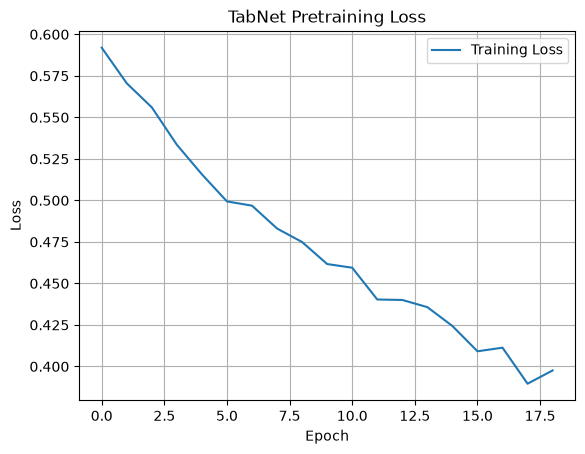

In [32]:
plt.plot(clf.history['loss'][1:], label='Training Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('TabNet Pretraining Loss')
plt.legend()
plt.grid(True)

plt.show()

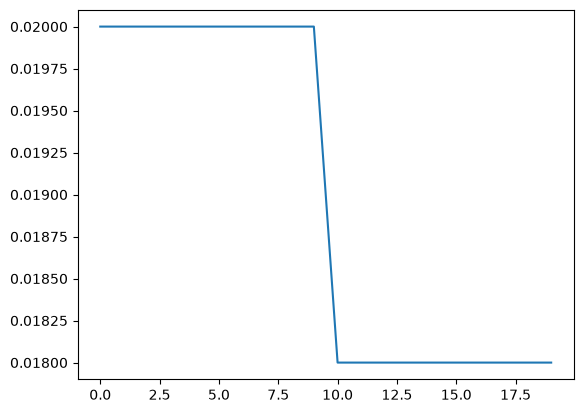

In [33]:

plt.plot(clf.history['lr']);

=== Importancia Global de Características ===
                Variable  Importancia
9            Temperature     0.514305
7                    EDA     0.097185
13                  Beta     0.088108
12                 Alpha     0.075065
14                 Gamma     0.059924
6     resmasknet_neutral     0.051420
0       resmasknet_anger     0.033705
5    resmasknet_surprise     0.024094
4     resmasknet_sadness     0.015247
1     resmasknet_disgust     0.013177
10                 Delta     0.012125
11                 Theta     0.009949
2        resmasknet_fear     0.003068
3   resmasknet_happiness     0.001855
8                    BVP     0.000773


/tmp/ipykernel_12957/2466763852.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=global_imp, x='Importancia', y='Variable', palette='viridis')


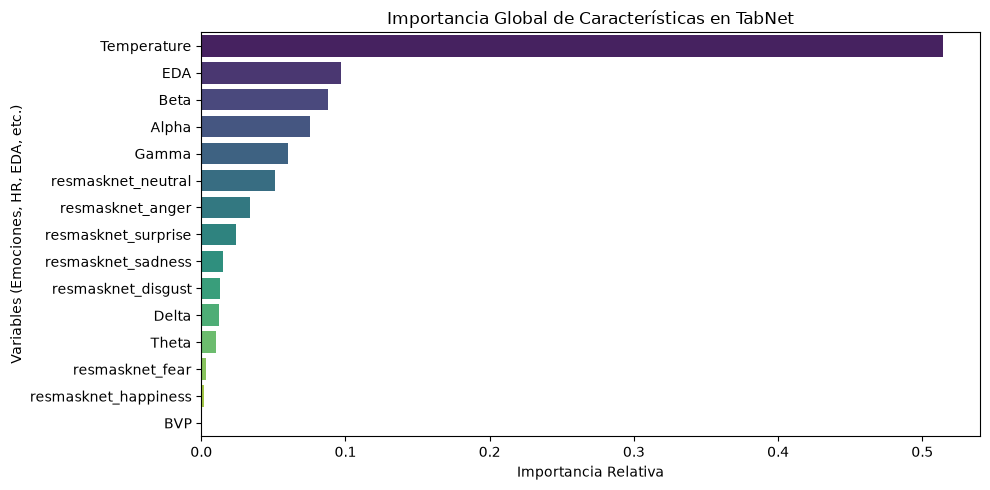

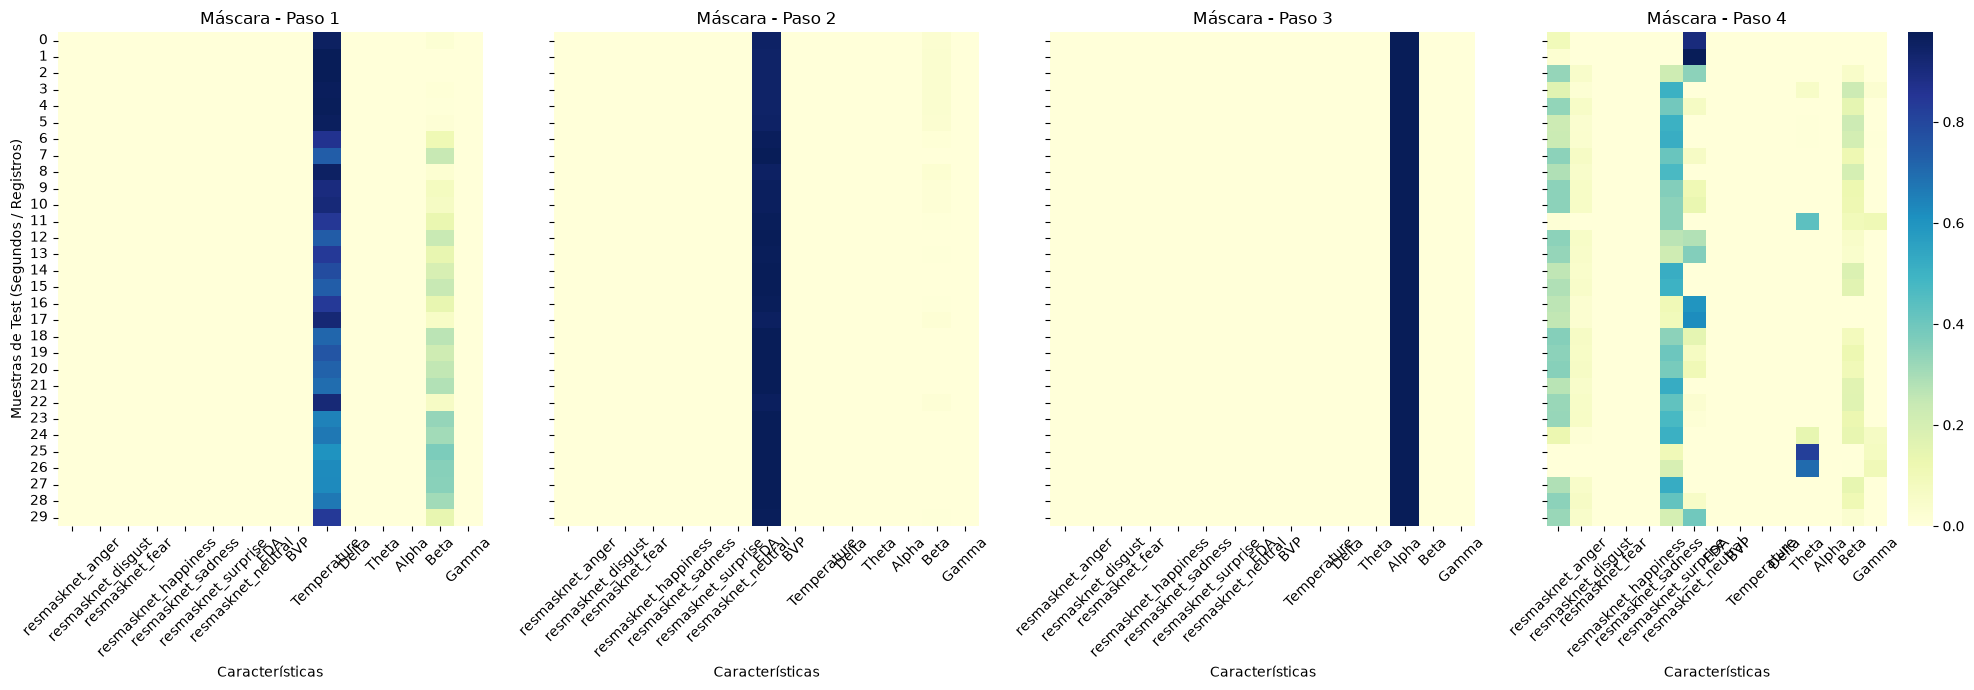

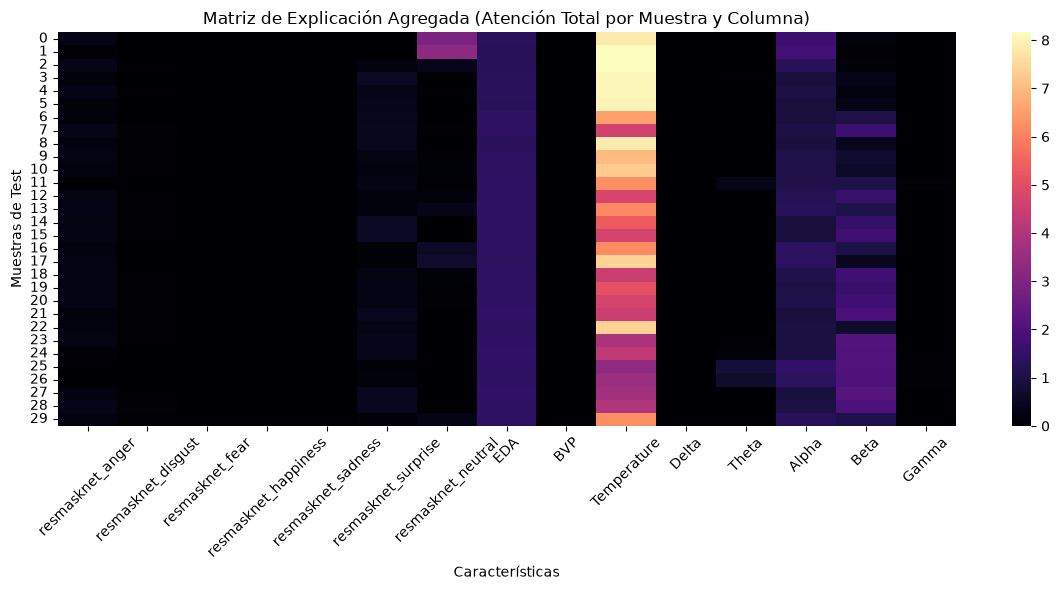

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraer la matriz de explicación global por fila y el diccionario de máscaras por paso
explain_matrix, masks = clf.explain(X_test)

# --- A. IMPORTANCIA GLOBAL (Ranking general de columnas) ---
global_imp = pd.DataFrame({
    'Variable': feature_cols,
    'Importancia': clf.feature_importances_
}).sort_values(by='Importancia', ascending=False)

print("=== Importancia Global de Características ===")
print(global_imp)

plt.figure(figsize=(10, 5))
sns.barplot(data=global_imp, x='Importancia', y='Variable', palette='viridis')
plt.title('Importancia Global de Características en TabNet')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variables (Emociones, HR, EDA, etc.)')
plt.tight_layout()
plt.show()


# --- B. MÁSCARAS DE ATENCIÓN POR PASO DE DECISIÓN (Local / Por Fila) ---
# Visualizamos las primeras 30 filas de X_test para ver qué columnas mira TabNet en cada paso
n_samples = 30
n_steps = len(masks)

fig, axes = plt.subplots(1, n_steps, figsize=(5 * n_steps, 7), sharey=True)

for step in range(n_steps):
    # masks[step] tiene forma (n_filas, n_columnas)
    sns.heatmap(
        masks[step][:n_samples],
        ax=axes[step],
        cmap='YlGnBu',
        xticklabels=feature_cols,
        cbar=(step == n_steps - 1)
    )
    axes[step].set_title(f'Máscara - Paso {step + 1}')
    axes[step].set_xlabel('Características')
    axes[step].tick_params(axis='x', rotation=45)

axes[0].set_ylabel('Muestras de Test (Segundos / Registros)')
plt.tight_layout()
plt.show()


# --- C. MATRIZ DE EXPLICACIÓN AGREGADA (Suma ponderada de todos los pasos) ---
plt.figure(figsize=(12, 6))
sns.heatmap(
    explain_matrix[:n_samples],
    cmap='magma',
    xticklabels=feature_cols
)
plt.title('Matriz de Explicación Agregada (Atención Total por Muestra y Columna)')
plt.xlabel('Características')
plt.ylabel('Muestras de Test')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()